Churn analysis 


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

file_path = Path(
    r"D:\DataAnylitics\Telcom_ChurnProject\Telco_Customer_Churn.csv"
)

if file_path.exists():
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully!")
    print(df.head())
    print("Dataset shape:", df.shape)
else:
    print("File not found. Please check the file path.")

Dataset loaded successfully!
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV Streami

In [2]:
charges = pd.to_numeric(
    df["MonthlyCharges"], errors="coerce"
).dropna().to_numpy()

print("Average Monthly Charges:", np.mean(charges))
print("Maximum Monthly Charges:", np.max(charges))
print("Minimum Monthly Charges:", np.min(charges))
print("Standard Deviation:", np.std(charges))

Average Monthly Charges: 64.76169246059918
Maximum Monthly Charges: 118.75
Minimum Monthly Charges: 18.25
Standard Deviation: 30.087910854936975


In [4]:
df.shape

(7043, 21)

Inspect and clean the data using Python

In [8]:
df.columns
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [9]:
print(df.dtypes)
print(df.info())

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents     

data quality checks

In [10]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
df["customerID"].duplicated().sum()

np.int64(0)

In [16]:
df['Churn'].value_counts(dropna=False)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Clean the data

In [17]:
df.colums = df.columns.str.strip()
df["TotalCharges"]= pd.to_numeric(
    df['TotalCharges'].astype(str).str.strip(), errors="coerce"
)
print(df['TotalCharges'].isnull().sum())

11


C:\Users\Admin\AppData\Local\Temp\ipykernel_24712\3980405023.py:1: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  df.colums = df.columns.str.strip()


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [21]:
print(df[df["TotalCharges"].isnull()].head(5))

      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
488   4472-LVYGI  Female              0     Yes        Yes       0   
753   3115-CZMZD    Male              0      No        Yes       0   
936   5709-LVOEQ  Female              0     Yes        Yes       0   
1082  4367-NUYAO    Male              0     Yes        Yes       0   
1340  1371-DWPAZ  Female              0     Yes        Yes       0   

     PhoneService     MultipleLines InternetService       OnlineSecurity  ...  \
488            No  No phone service             DSL                  Yes  ...   
753           Yes                No              No  No internet service  ...   
936           Yes                No             DSL                  Yes  ...   
1082          Yes               Yes              No  No internet service  ...   
1340           No  No phone service             DSL                  Yes  ...   

         DeviceProtection          TechSupport          StreamingTV  \
488                  

In [23]:
df.loc[
    df['TotalCharges'].isnull() & df['tenure'].eq(0),"totalCharges"] = 0


Create useful analysis columns

In [7]:
df["ChurnFlag"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, float("inf")],
    labels=["0-12 Months", "13-24 Months",
            "25-48 Months", "49+ Months"]
)

df["MonthlyChargeGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[-float("inf"), 35, 70, float("inf")],
    labels=["Low", "Medium", "High"]
)

print(df[["Churn", "ChurnFlag",
          "TenureGroup", "MonthlyChargeGroup"]].head())

  Churn  ChurnFlag   TenureGroup MonthlyChargeGroup
0    No          0   0-12 Months                Low
1    No          0  25-48 Months             Medium
2   Yes          1   0-12 Months             Medium
3    No          0  25-48 Months             Medium
4   Yes          1   0-12 Months               High


In [3]:
output_path = (
   r"D:\DataAnylitics\Telcom_ChurnProject\Telco_Customer_Churn.csv"

)
print("cleaned dataset saved successfuly")

cleaned dataset saved successfuly


Create a Charts

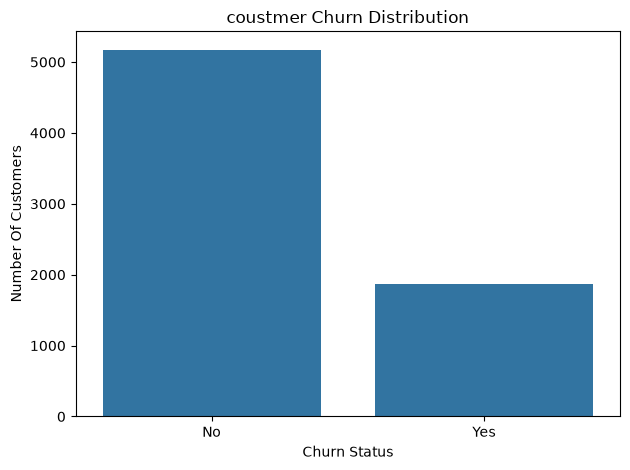

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_csv(  r"D:\DataAnylitics\Telcom_ChurnProject\Telco_Customer_Churn.csv")
sns.countplot(data=df,x="Churn")

plt.title("coustmer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number Of Customers")
plt.tight_layout()
plt.show()

Calculate the core KPIs

In [9]:
total_customers = df['customerID'].nunique()

churned_customers = (
    df.loc[df["Churn"] == "Yes","customerID"].nunique()
)

retained_customer = (
    df.loc[df["Churn"] == "No","customerID"].nunique()

)
churn_rate = churned_customers / total_customers * 100

print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print("Retained customers:", retained_customer)
print("Churn rate:", round(churn_rate, 2), "%")


Total customers: 7043
Churned customers: 1869
Retained customers: 5174
Churn rate: 26.54 %


Analyze churn by contract

In [10]:
contract_Analysis = (
    df.groupby("Contract",dropna=False)
    .agg(
        total_customers =('customerID','nunique'),
        churned_customers=('ChurnFlag','mean')

    ).reset_index()
)
contract_Analysis['churn_rate'] *= 100

print(
    contract_Analysis.sort_values(
        "churn_rate",ascending=False
    )
)

KeyError: 'churn_rate'

In [11]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'ChurnFlag', 'TenureGroup', 'MonthlyChargeGroup']


In [13]:

contract_Analysis = (
    df.groupby("Contract", dropna=False)
    .agg(
        total_customers=("customerID", "nunique"),
        churn_rate=("ChurnFlag", "mean")
    )
    .reset_index()
)

contract_Analysis["churn_rate"] *= 100

print(
    contract_Analysis.sort_values(
        "churn_rate", ascending=False
    )
)


         Contract  total_customers  churn_rate
0  Month-to-month             3875   42.709677
1        One year             1473   11.269518
2        Two year             1695    2.831858


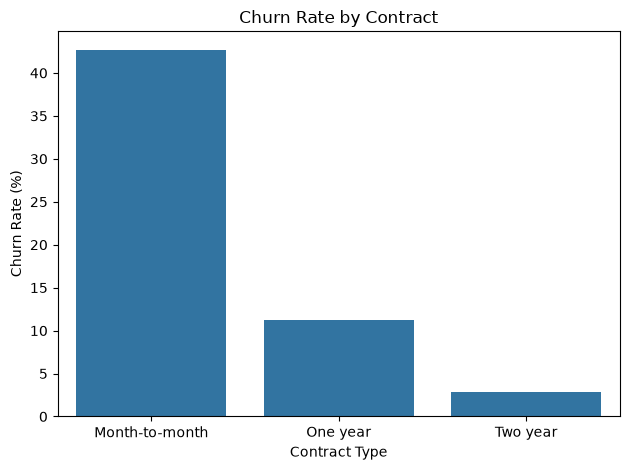

In [15]:

sns.barplot(
    data=contract_Analysis,
    x="Contract",
    y="churn_rate"
)

plt.title("Churn Rate by Contract")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Contract Type")
plt.tight_layout()
plt.show()


Analyze churn by tenure

In [16]:
tenure_analysis = (
    df.groupby("TenureGroup", observed=True)
      .agg(
          TotalCustomers=("customerID", "nunique"),
          ChurnedCustomers=("ChurnFlag", "sum"),
          ChurnRate=("ChurnFlag", "mean")
      )
      .reset_index()
)

tenure_analysis["ChurnRate"] *= 100

print(tenure_analysis)

    TenureGroup  TotalCustomers  ChurnedCustomers  ChurnRate
0   0-12 Months            2186              1037  47.438243
1  13-24 Months            1024               294  28.710938
2  25-48 Months            1594               325  20.388959
3    49+ Months            2239               213   9.513176


Analyze monthly charges

In [17]:
print(
    df.groupby("Churn")["MonthlyCharges"]
      .agg(["count", "mean", "median"])
)

       count       mean  median
Churn                          
No      5174  61.265124  64.425
Yes     1869  74.441332  79.650


Explore several variables together

In [18]:
segment_analysis = (
    df.groupby(
        ["Contract", "InternetService"],
        dropna=False
    )
    .agg(
        TotalCustomers=("customerID", "nunique"),
        ChurnRate=("ChurnFlag", "mean")
    )
    .reset_index()
)

segment_analysis["ChurnRate"] *= 100

print(
    segment_analysis.sort_values(
        "ChurnRate", ascending=False
    )
)

         Contract InternetService  TotalCustomers  ChurnRate
1  Month-to-month     Fiber optic            2128  54.605263
0  Month-to-month             DSL            1223  32.215863
4        One year     Fiber optic             539  19.294991
2  Month-to-month              No             524  18.893130
3        One year             DSL             570   9.298246
7        Two year     Fiber optic             429   7.226107
5        One year              No             364   2.472527
6        Two year             DSL             628   1.910828
8        Two year              No             638   0.783699


In [ ]:
df = np.mean(['TotalCharges'])